# Model Scaling Calculator

This notebook implements the scaling relationships developed in the paired model scaling tutorial to estimate the computing resources required to train dense transformer models.

Given a model size, tokens-per-parameter ratio, model FLOPs utilization (MFU), and available training time, we will estimate:

1. The number of GPUs required to complete training within the available time.
2. The number of GPUs required to store the model's training states in memory.
3. The total number of GPUs required to satisfy both constraints.

We will compare several GPU architectures to visualize how the resource requirements scale with model size for a set of popular GPUs.

The calculator uses the simplified compute relationship $C(\mu) \approx 6r\mu^2$ and assumes fully sharded training states with 16 bytes per parameter. As with the estimates developed in the tutorial, these estimates are intended for initial resource planning rather than detailed cluster design.

## GPU Specifications

We will compare five GPUs using their approximate peak BF16 throughput and onboard memory capacity. Throughput is expressed in TFLOPs/s and memory in GB ($10^9$ bytes). These are approximate planning values. Actual throughput depends on numerical precision, hardware configuration, and whether sparsity acceleration is used. We assume dense BF16 operations to select the values below. If a different precision is to be used, it is necessary to check the manufacturer's specifications at the precision.

In [1]:
%matplotlib widget

import matplotlib.pyplot as plt
import numpy as np

# Approximate peak dense BF16 throughput and GPU memory
gpus = {
    "RTX 5090": {"tflops": 210, "memory": 32},
    "A100 80GB": {"tflops": 312, "memory": 80},
    "H100 SXM": {"tflops": 989, "memory": 80},
    "H200 SXM": {"tflops": 989, "memory": 141},
    "B300 SXM": {"tflops": 2250, "memory": 270},
}


## Scaling Calculator

The following function implements the compute and memory scaling relationships we derived in the tutorial. For each GPU, we calculate the compute-limited and memory-limited GPU counts, then take the maximum to determine the total requirement. The function prints a summary of the selected model and generates three plots showing how GPU requirements change with model size.

In [2]:
def gpu_scaling(
    parameters=7e9,
    tokens_per_parameter=20,
    eta=0.40,
    days=30,
    memory_reserve=0.25,
):
    """Estimate GPU requirements for dense transformer training."""
    tokens, flops, memory, seconds = compute_training_parameters(
        parameters, tokens_per_parameter, days
    )
    model_sizes, model_flops, model_memory = compute_model_sizes_for_plotting(
        tokens_per_parameter
    )
    results = {}
    curves = {}
    for name, gpu in gpus.items():
        throughput, available_memory = compute_effective_gpu_resources(
            eta, memory_reserve, gpu
        )
        n_compute, n_memory, n_total = compute_gpu_counts(
            flops, memory, seconds, throughput, available_memory
        )
        compute_curve, memory_curve, total_curve = compute_gpu_count_curves(
            seconds, model_flops, model_memory, throughput, available_memory
        )
        results[name] = (n_compute, n_memory, n_total)
        curves[name] = (compute_curve, memory_curve, total_curve)

    print_scaling_summary(
        parameters, eta, days, memory_reserve, tokens, flops, memory, results
    )
    plot_scaling_relationships(parameters, eta, days, model_sizes, curves)

    return results


def plot_scaling_relationships(parameters, eta, days, model_sizes, curves):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    titles = [
        "Compute-Limited GPUs",
        "Memory-Limited GPUs",
        "Combined GPU Requirement",
    ]

    for i, ax in enumerate(axes):
        for name, curve in curves.items():
            ax.plot(model_sizes / 1e9, curve[i], label=name)

        ax.axvline(
            parameters / 1e9,
            color="gray",
            linestyle="--",
            alpha=0.7,
        )

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel("Model Parameters (Billions)")
        ax.set_ylabel("Required GPUs")
        ax.set_title(titles[i])
        ax.grid(True, which="both", alpha=0.3)

    axes[0].legend()
    fig.suptitle(
        f"Model Scaling | {parameters / 1e9:.2f}B Parameters | "
        f"{days:g} Days | MFU = {eta:.0%}"
    )

    plt.tight_layout()
    plt.show()


def print_scaling_summary(
    parameters, eta, days, memory_reserve, tokens, flops, memory, results
):
    print(f"Model parameters: {parameters / 1e9:.2f}B")
    print(f"Training tokens:  {tokens / 1e9:.2f}B")
    print(f"Training compute: {flops:.3e} FLOPs")
    print(f"Training memory:  {memory:.2f} GB")
    print(f"Training time:    {days} days")
    print(f"MFU:              {eta:.0%}")
    print(f"Memory reserve:   {memory_reserve:.0%}\n")

    print(f"{'GPU':<15} {'Compute':>10} {'Memory':>10} {'Total':>10}")
    print("-" * 48)

    for name, (nc, nm, nt) in results.items():
        print(f"{name:<15} {nc:>10} {nm:>10} {nt:>10}")


def compute_gpu_count_curves(
    seconds, model_flops, model_memory, throughput, available_memory
):
    compute_curve = np.ceil(model_flops / (seconds * throughput))
    memory_curve = np.ceil(model_memory / available_memory)
    total_curve = np.maximum(compute_curve, memory_curve)
    return compute_curve, memory_curve, total_curve


def compute_gpu_counts(flops, memory, seconds, throughput, available_memory):
    n_compute = int(np.ceil(flops / (seconds * throughput)))
    n_memory = int(np.ceil(memory / available_memory))
    n_total = max(n_compute, n_memory)
    return n_compute, n_memory, n_total


def compute_effective_gpu_resources(eta, memory_reserve, gpu):
    throughput = gpu["tflops"] * 1e12 * eta
    available_memory = gpu["memory"] * (1 - memory_reserve)
    return throughput, available_memory


def compute_model_sizes_for_plotting(tokens_per_parameter):
    model_sizes = np.logspace(8, 11.5, 300)
    model_flops = 6 * tokens_per_parameter * model_sizes**2
    model_memory = 16 * model_sizes / 1e9
    return model_sizes, model_flops, model_memory


def compute_training_parameters(parameters, tokens_per_parameter, days):
    tokens = tokens_per_parameter * parameters
    flops = 6 * parameters * tokens
    memory = 16 * parameters / 1e9  # GB
    seconds = days * 86400
    return tokens, flops, memory, seconds


## Experiment: GPU Scaling

We can now use the calculator to estimate the resources required to train a model.

We will start with the 7-billion-parameter model from the tutorial, using a tokens-per-parameter ratio of 20, an MFU of 40%, and a training deadline of 30 days.

The dashed vertical lines in the plots indicate our selected model size. Change the parameters below to explore how GPU requirements change with model size, training time, and utilization.

Model parameters: 7.00B
Training tokens:  140.00B
Training compute: 5.880e+21 FLOPs
Training memory:  112.00 GB
Training time:    30 days
MFU:              40%
Memory reserve:   25%

GPU                Compute     Memory      Total
------------------------------------------------
RTX 5090                28          5         28
A100 80GB               19          2         19
H100 SXM                 6          2          6
H200 SXM                 6          2          6
B300 SXM                 3          1          3


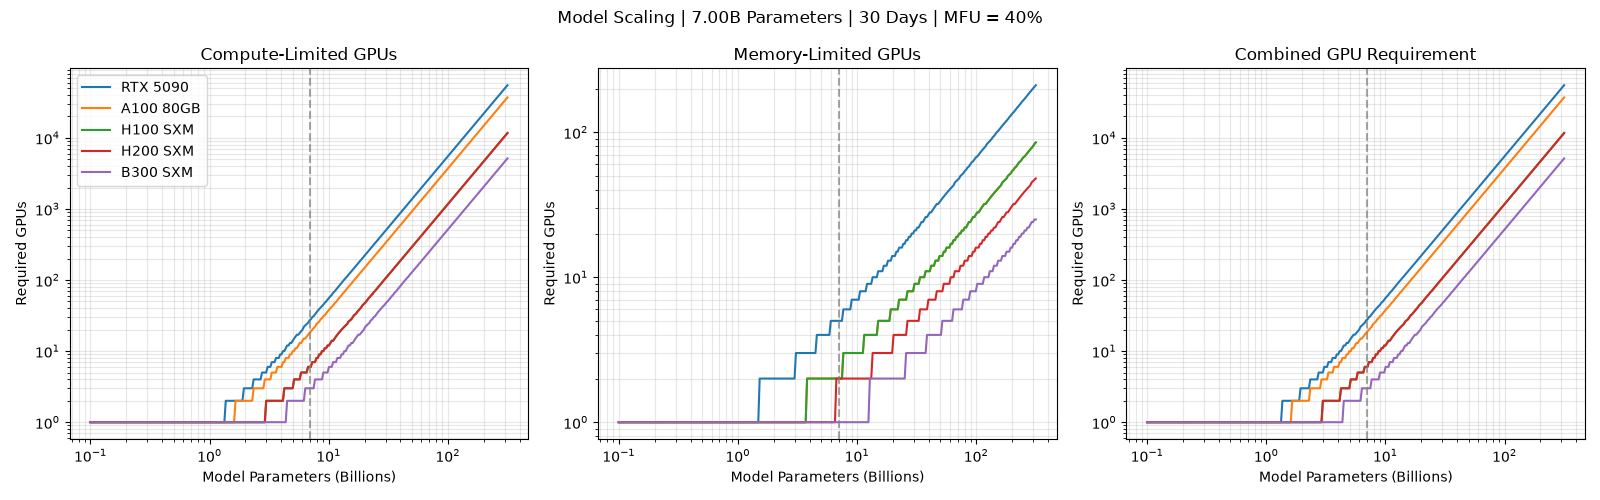

In [3]:
# Experiment parameters
parameters = 7e9
tokens_per_parameter = 20
eta = 0.40
days = 30
memory_reserve = 0.25

results = gpu_scaling(
    parameters=parameters,
    tokens_per_parameter=tokens_per_parameter,
    eta=eta,
    days=days,
    memory_reserve=memory_reserve,
)


## Interactive Scaling Calculator

Here we use `ipywidgets` to explore the scaling relationships interactively. Adjust the sliders to change the model size, training deadline, MFU, and other assumptions.


In [4]:
import ipywidgets as widgets
from IPython.display import display

controls = {
    "parameters": widgets.FloatLogSlider(
        value=7e9,
        base=10,
        min=8,
        max=11.5,
        step=0.1,
        description="Parameters",
        readout_format=".2e",
    ),
    "tokens_per_parameter": widgets.IntSlider(
        value=20,
        min=1,
        max=100,
        description="Tokens/Param",
    ),
    "eta": widgets.FloatSlider(
        value=0.40,
        min=0.05,
        max=1.0,
        step=0.05,
        description="MFU",
    ),
    "days": widgets.FloatLogSlider(
        value=30,
        base=10,
        min=0,
        max=3,
        step=0.1,
        description="Days",
        readout_format=".1f",
    ),
    "memory_reserve": widgets.FloatSlider(
        value=0.25,
        min=0,
        max=0.75,
        step=0.05,
        description="Mem Reserve",
        readout_format=".0%",
    ),
}

output = widgets.interactive_output(gpu_scaling, controls)
display(widgets.VBox([*controls.values(), output]))
